# EDA: данные распределённых оптоволоконных сенсоров (6 CSV)

Воспроизводимый анализ. Весь разбор выполняется модулем `src/data_loader.py` (тот же, что в пайплайне), графики — `src/eda.py`. Выводы — в `docs/DATA_REPORT.md`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import eda
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
sources = eda.load_sources()
[s.source_id for s in sources]

['1', '2', '3', '4', '5', '6']

## 1. Схема, объём, время, приборы и каналы
Каждый файл содержит ровно одну пару (прибор, канал). `points_size` есть только в 1.csv и 6.csv и везде совпадает с фактической длиной.

In [2]:
summary = eda.summary_table(sources)
summary.T

source_id,1,2,3,4,5,6
file,1.csv,2.csv,3.csv,4.csv,5.csv,6.csv
dts_id,0e0d0f3c-cfe2-456e-bc2c-e0b6d27be9cb,cd477c43-772c-4725-a33a-b0c77bbfe8c9,cd477c43-772c-4725-a33a-b0c77bbfe8c9,cd477c43-772c-4725-a33a-b0c77bbfe8c9,mapping_ch02,5f895b10-971c-4b27-9a03-85be67fd1aab
channel_id,1,1,2,2,2,1
rows_raw,615,696,788,708,2711,1231
rows_valid,615,696,788,708,2711,1231
rows_rejected,0,0,0,0,0,0
time_start,2026-09-13 21:03:19+00:00,2026-04-10 00:01:41+00:00,2026-02-12 00:01:54+00:00,2026-05-26 00:01:53+00:00,2025-10-16 12:00:06+00:00,2026-02-11 21:00:01+00:00
time_end,2026-09-14 09:04:22+00:00,2026-04-10 23:58:41+00:00,2026-02-13 23:59:25+00:00,2026-05-26 23:59:07+00:00,2025-10-16 21:07:00+00:00,2026-02-12 20:59:51+00:00
tz_known,True,True,True,True,False,True
tz_offset_h,3.0,0.0,0.0,0.0,NaN,3.0


## 2. Проблемы качества по строкам (отбракованные строки и причины)

In [3]:
{s.source_id: (s.issues['reason'].value_counts().to_dict() if len(s.issues) else 'нет') for s in sources}

{'1': 'нет', '2': 'нет', '3': 'нет', '4': 'нет', '5': 'нет', '6': 'нет'}

## 3. Шум и изменчивость
`frame_diff_std_median` — типичный разброс разности соседних кадров (оценка шума измерения).

In [4]:
eda.noise_stats(sources)

,frame_diff_std_median,spatial_diff_std,temporal_std_median,temporal_std_p95
source_id,,,,
1,0.735424,0.806801,1.010069,5.731097
2,0.395344,0.468374,0.440588,1.493682
3,0.442170,0.443040,0.748768,1.476837
4,0.366516,0.371349,0.286179,1.911629
5,1.258563,1.242187,0.925412,1.056942
6,0.833414,0.816213,0.760701,1.050300


## 4. Распределения, шаги по времени, пропуски по координате

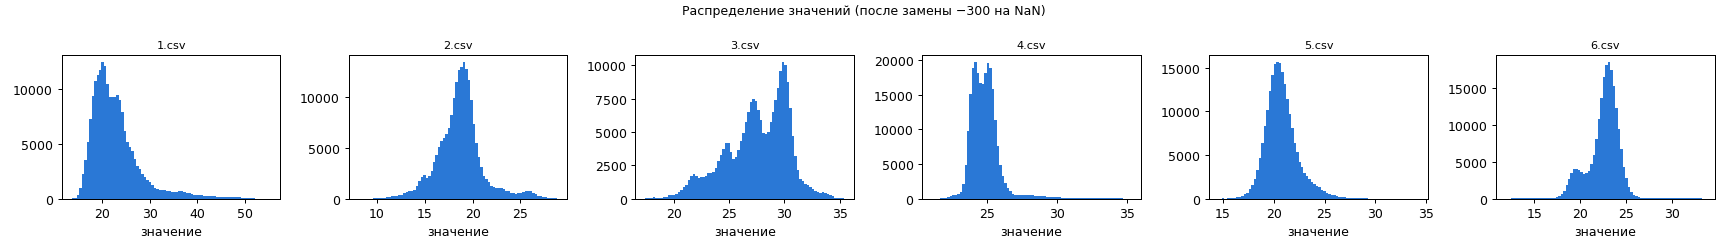

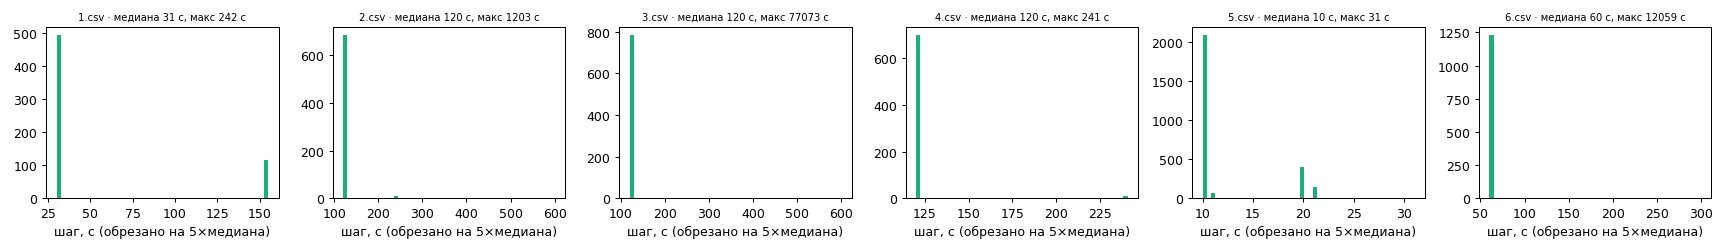

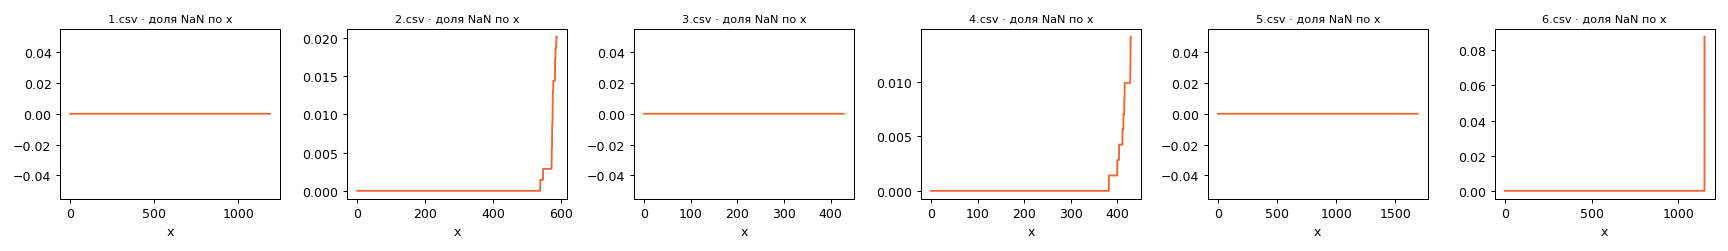

In [5]:
paths = eda.plot_overview(sources)
for p in paths[:3]:
    display(Image(filename=str(p)))

## 5. Тепловые карты «кадр × координата»
Слева — значения, в центре — отклонение от медианы по времени, справа — несколько профилей.

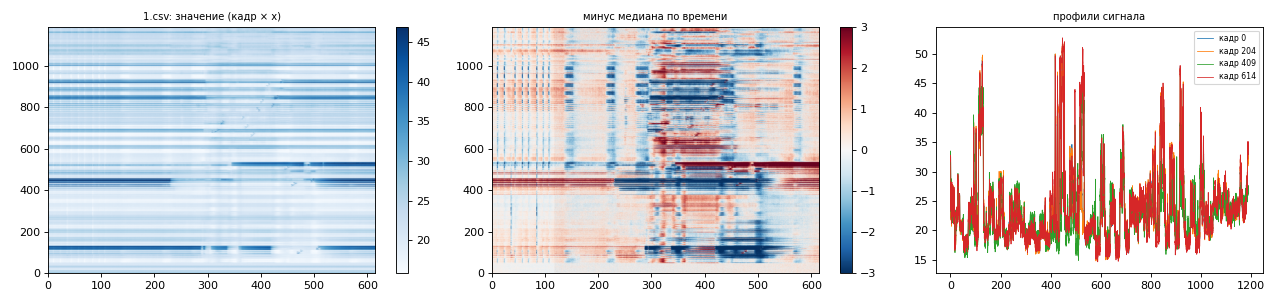

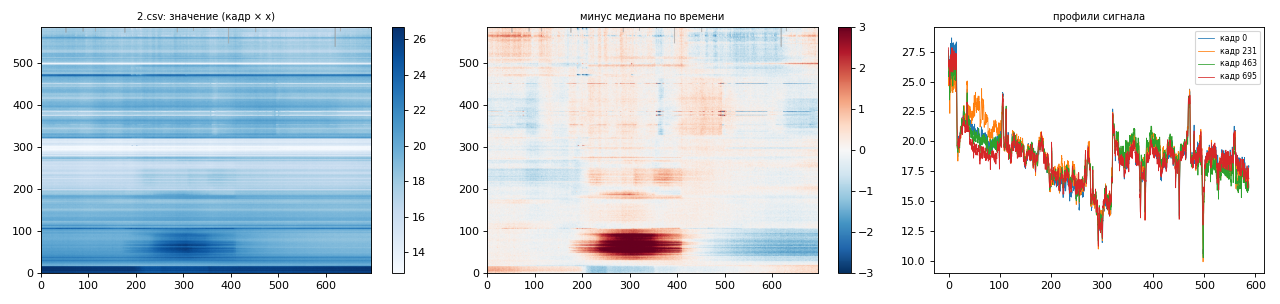

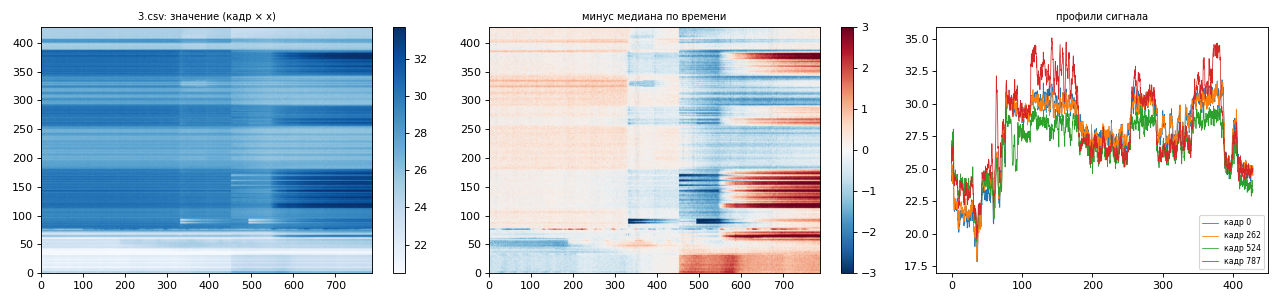

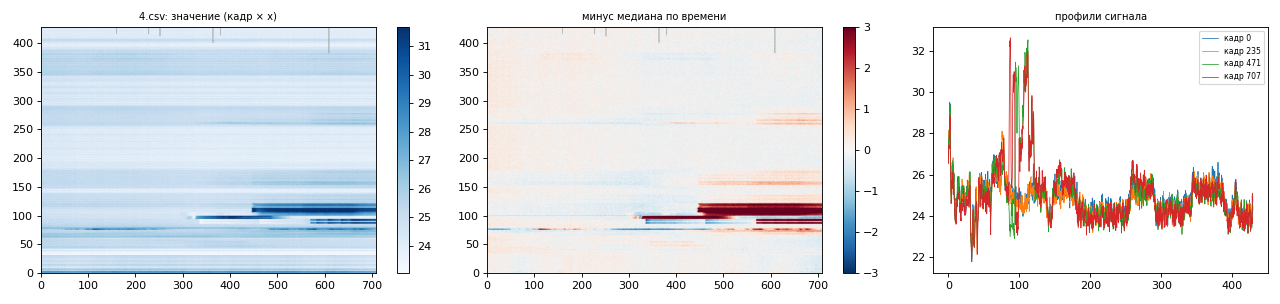

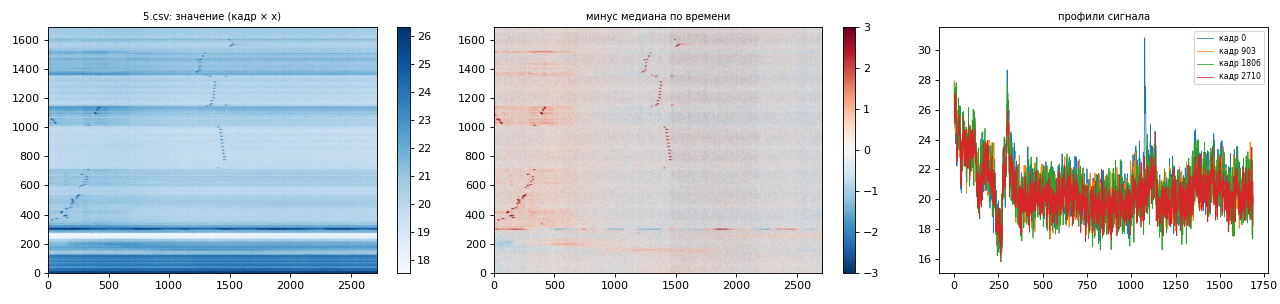

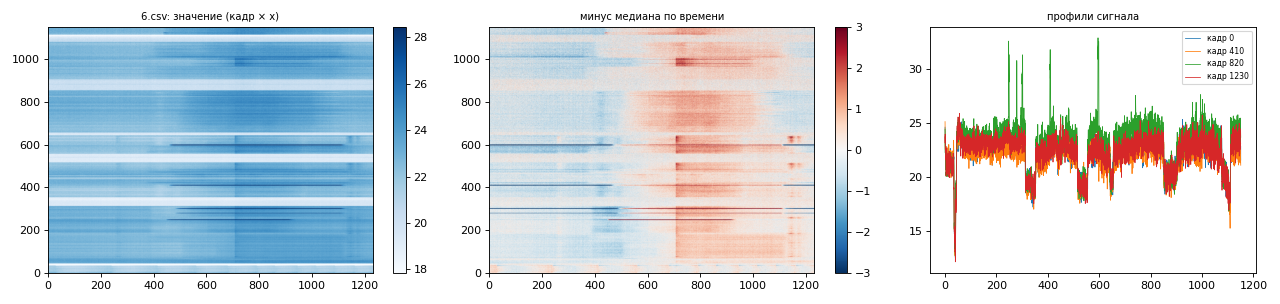

In [6]:
for p in paths[3:]:
    display(Image(filename=str(p)))

## 6. Ключевые наблюдения
* Формат `points` — JSON-массив пар `[x, value]`, x от 0 с постоянным шагом (0.1015 в 1.csv; ≈0.2538 в 2–4, 6; 1.0 в 5.csv).
* Файл 5: `dts_id = mapping_ch02`, без часового пояса, шаг 10 с, значения округлены до 4 знаков, столбцы 1689–2363 равны −300 во всех кадрах → заполнитель за концом волокна.
* Файлы 2, 4, 6 содержат укороченные профили (меньше точек в отдельных кадрах) → хвост заполняется NaN.
* Файл 1: опрос каждые 4 мин, затем каждые 30 с; файл 3 содержит разрыв 21 ч; файл 6 — разрыв 3.3 ч.
* Значения 6–56 и названия `dts_id` указывают на DTS (температуру, °C) — не подтверждено.
* Соответствие каналов кабелям в данных отсутствует.